In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, balanced_accuracy_score

pd.set_option("display.max_columns", 100)

CLASS_NAMES = {0:"Not warm / OK", 1:"Warm", 2:"Too hot"}
ORDER = ["Not warm / OK", "Warm", "Too hot"]
FEATURES = ["temperature_c","relative_humidity","wind_speed_10m_ms","shortwave_radiation_wm2"]

def find_data():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd/"thermosurvey_historical_weather_enriched.csv",
        cwd/"data"/"processed"/"thermosurvey_historical_weather_enriched.csv",
        cwd/"ai"/"thermal_model"/"data"/"processed"/"thermosurvey_historical_weather_enriched.csv",
        Path("/mnt/data/thermosurvey_historical_weather_enriched.csv"),
    ]
    for base in [cwd, *cwd.parents]:
        candidates += [
            base/"data"/"processed"/"thermosurvey_historical_weather_enriched.csv",
            base/"ai"/"thermal_model"/"data"/"processed"/"thermosurvey_historical_weather_enriched.csv",
        ]
    for x in candidates:
        if x.exists():
            return x
    raise FileNotFoundError("thermosurvey_historical_weather_enriched.csv not found")

DATA_PATH = find_data()
df = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH)
print("Raw shape:", df.shape)


Using: ai/thermal_model\data\processed\thermosurvey_historical_weather_enriched.csv
Raw shape: (2099, 22)


## 1. Prepare the same outdoor/semi-outdoor analysis set

Keep `e7 = 2 or 3` and rows with a valid target plus complete weather features.


Usable rows: 689


,count,percentage
thermal_class,,
Not warm / OK,246,35.70
Warm,230,33.38
Too hot,213,30.91


thermal_class,Not warm / OK,Too hot,Warm
city,,,
Madrid,64,159,81
Warsaw,182,54,149


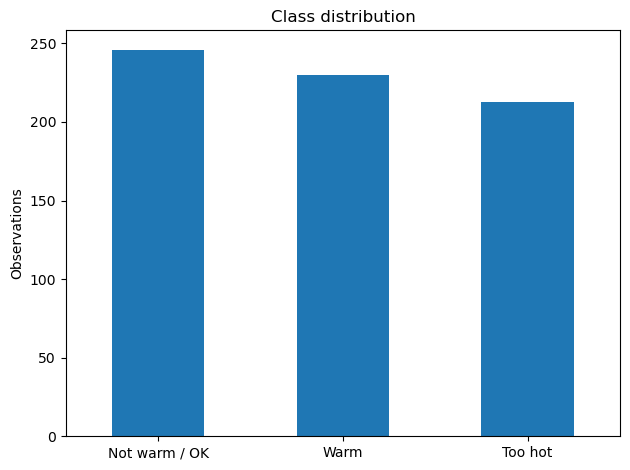

In [2]:
required = ["nr","city","e7","thermal_class_code",*FEATURES]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing columns: {missing}")

data = df[df["e7"].isin([2,3])].copy()
data = data.dropna(subset=["thermal_class_code",*FEATURES]).copy()
data["thermal_class_code"] = data["thermal_class_code"].astype(int)
data["thermal_class"] = data["thermal_class_code"].map(CLASS_NAMES)

print("Usable rows:", len(data))
counts = data["thermal_class"].value_counts().reindex(ORDER)
display(pd.DataFrame({"count":counts, "percentage":(100*counts/len(data)).round(2)}))
display(pd.crosstab(data["city"], data["thermal_class"]))

ax = counts.plot(kind="bar")
ax.set_title("Class distribution")
ax.set_xlabel("")
ax.set_ylabel("Observations")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()


## 2. Environmental distributions by class

If the classes were naturally easy to separate, their weather distributions would occupy clearly different ranges. The following summaries and boxplots show the overlap directly.


temperature_c                                 relative_humidity  \
                      count   mean median   std   min   max             count   
thermal_class                                                                   
Not warm / OK           246  25.78  25.75  3.51  17.0  39.7               246   
Too hot                 213  32.69  32.50  2.97  21.4  39.2               213   
Warm                    230  29.38  29.40  2.85  20.5  37.5               230   

                                               wind_speed_10m_ms               \
                mean median    std   min   max             count  mean median   
thermal_class                                                                   
Not warm / OK  45.30  45.55  12.96  15.2  87.2               246  3.35   3.20   
Too hot        30.41  27.40   9.67  12.0  58.5               213  2.89   2.82   
Warm           41.33  41.15  11.84  15.0  74.9               230  2.90   2.74   

                                shortwave_radiation_wm2                 \
                std   min   max                   count    mean median   
thermal_class                                                            
Not warm / OK  1.56  0.50  7.86                     246  421.69  423.0   
Too hot        1.45  0.50  8.41                     213  468.66  494.0   
Warm           1.39  0.28  7.86                     230  457.24  476.5   

                                   
                  std  min    max  
thermal_class                      
Not warm / OK  237.68  0.0  907.0  
Too hot        300.00  0.0  947.0  
Warm           246.59  0.0  916.0

[local notebook temp file]:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(vals, labels=ORDER, showfliers=True)


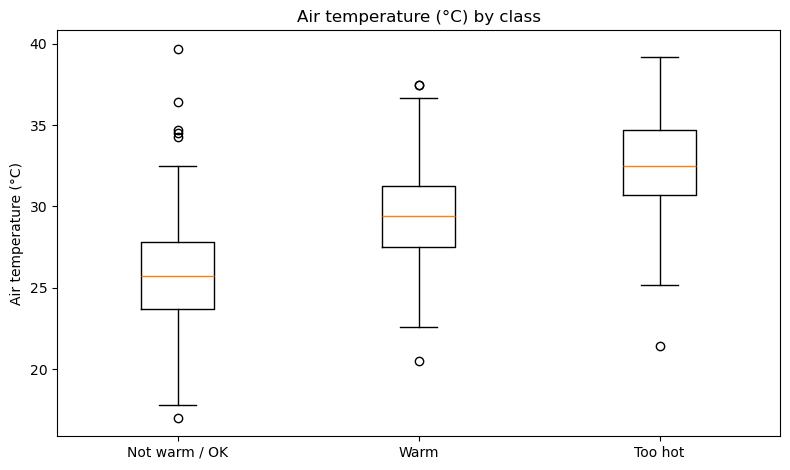

[local notebook temp file]:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(vals, labels=ORDER, showfliers=True)


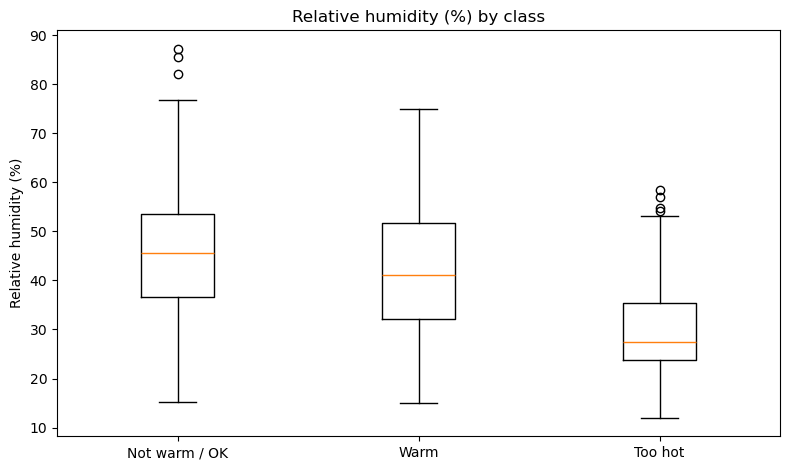

[local notebook temp file]:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(vals, labels=ORDER, showfliers=True)


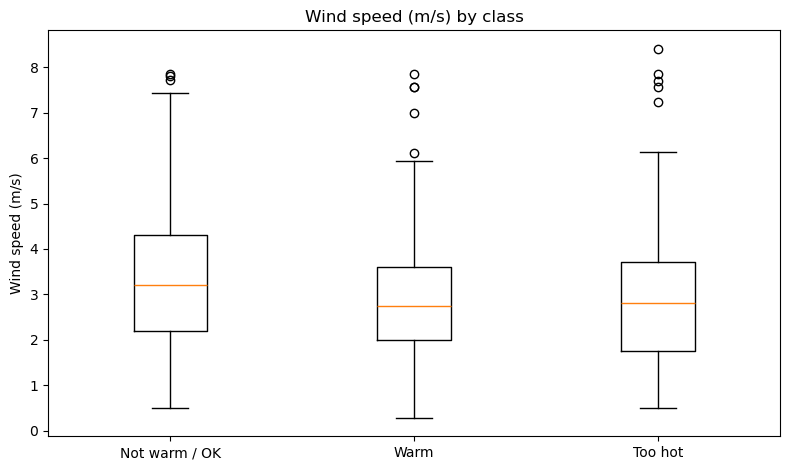

[local notebook temp file]:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(vals, labels=ORDER, showfliers=True)


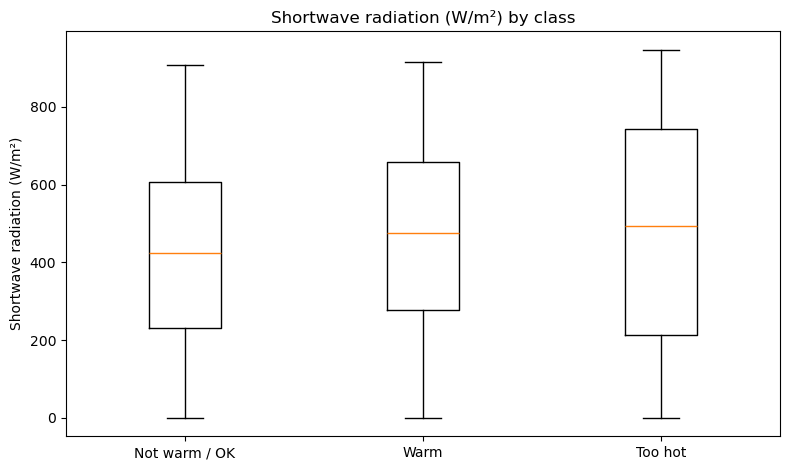

In [3]:
summary = data.groupby("thermal_class")[FEATURES].agg(["count","mean","median","std","min","max"]).round(2)
display(summary)

for feature, label in [
    ("temperature_c","Air temperature (°C)"),
    ("relative_humidity","Relative humidity (%)"),
    ("wind_speed_10m_ms","Wind speed (m/s)"),
    ("shortwave_radiation_wm2","Shortwave radiation (W/m²)")
]:
    vals = [data.loc[data["thermal_class"]==c, feature].values for c in ORDER]
    fig, ax = plt.subplots(figsize=(8,4.8))
    ax.boxplot(vals, labels=ORDER, showfliers=True)
    ax.set_title(f"{label} by class")
    ax.set_ylabel(label)
    plt.tight_layout(); plt.show()


## 3. Temperature × humidity overlap

This plot is useful for a mentor discussion because it shows that `Warm` does not form a clean, separate cluster.


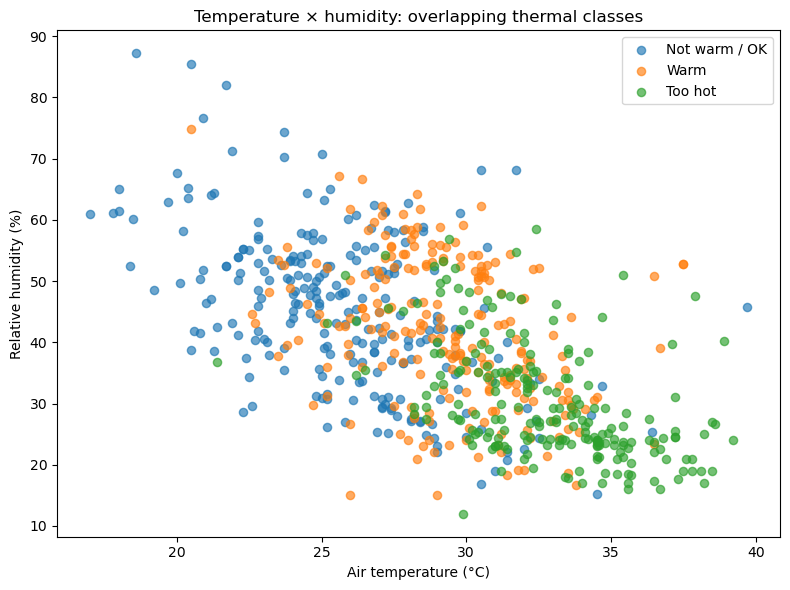

In [4]:
fig, ax = plt.subplots(figsize=(8,6))
for cls in ORDER:
    s = data[data["thermal_class"]==cls]
    ax.scatter(s["temperature_c"], s["relative_humidity"], alpha=0.65, s=35, label=cls)
ax.set_title("Temperature × humidity: overlapping thermal classes")
ax.set_xlabel("Air temperature (°C)")
ax.set_ylabel("Relative humidity (%)")
ax.legend()
plt.tight_layout(); plt.show()


## 4. Same or near-identical weather, different labels

Two diagnostics are used:

1. **Exact match:** identical temperature and humidity but different classes.
2. **Near match:** within ±0.5°C and ±2% RH but a different class.

The second test is particularly useful for showing how frequently people under almost the same conditions report different sensations.


Repeated exact temp/RH combinations: 12
Repeated exact combinations with conflicting classes: 4


,temperature_c,relative_humidity,n,n_classes,classes
198,27.0,45.0,2,2,"Not warm / OK, Warm"
386,30.0,36.9,2,2,"Too hot, Warm"
403,30.4,35.1,2,2,"Too hot, Warm"
497,31.9,47.1,2,2,"Too hot, Warm"


,count,sum,percentage
thermal_class,,,
Not warm / OK,246,158,64.23
Warm,230,204,88.70
Too hot,213,151,70.89


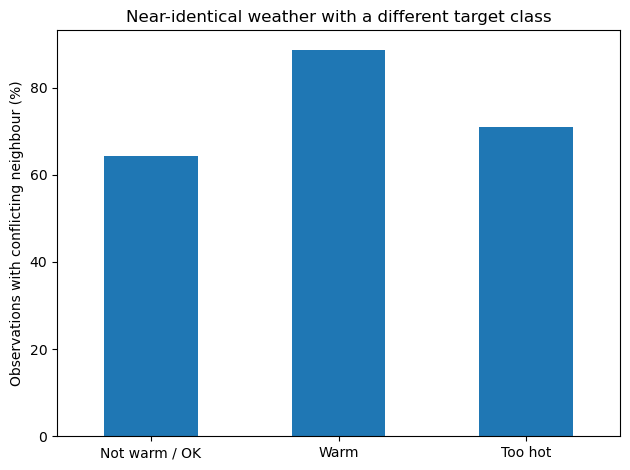

In [5]:
same_env = (
    data.groupby(["temperature_c","relative_humidity"])
    .agg(n=("nr","size"), n_classes=("thermal_class_code","nunique"),
         classes=("thermal_class", lambda s:", ".join(sorted(set(s)))))
    .reset_index()
)
exact_conflicts = same_env[(same_env["n"]>=2) & (same_env["n_classes"]>=2)]

print("Repeated exact temp/RH combinations:", int((same_env["n"]>=2).sum()))
print("Repeated exact combinations with conflicting classes:", len(exact_conflicts))
display(exact_conflicts.sort_values(["n_classes","n"], ascending=False).head(20))

temps = data["temperature_c"].to_numpy()
rhs = data["relative_humidity"].to_numpy()
y = data["thermal_class_code"].to_numpy()
flag = np.zeros(len(data), dtype=bool)

for i in range(len(data)):
    close = (np.abs(temps-temps[i])<=0.5) & (np.abs(rhs-rhs[i])<=2.0)
    close[i] = False
    flag[i] = np.any(close & (y != y[i]))

data["near_weather_conflict"] = flag
near = data.groupby("thermal_class")["near_weather_conflict"].agg(["count","sum","mean"]).reindex(ORDER)
near["percentage"] = 100*near["mean"]
display(near[["count","sum","percentage"]].round(2))

ax = near["percentage"].plot(kind="bar")
ax.set_title("Near-identical weather with a different target class")
ax.set_xlabel("")
ax.set_ylabel("Observations with conflicting neighbour (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()


## 5. Nearest-neighbour overlap in the full 4-feature weather space

All four weather features are standardized. For each observation, we find its 10 nearest environmental neighbours.

Two quantities are reported:
- **same-class neighbour share**
- whether the **majority** of nearby observations belongs to another class

A low same-class share for `Warm` means the middle class is locally mixed with both neighbouring classes.


,count,mean,median,std,mean_same_class_percent
thermal_class,,,,,
Not warm / OK,246,0.580,0.7,0.278,58.008
Warm,230,0.444,0.4,0.200,44.391
Too hot,213,0.571,0.6,0.280,57.089


,count,sum,percentage
thermal_class,,,
Not warm / OK,246,76,30.89
Warm,230,116,50.43
Too hot,213,84,39.44


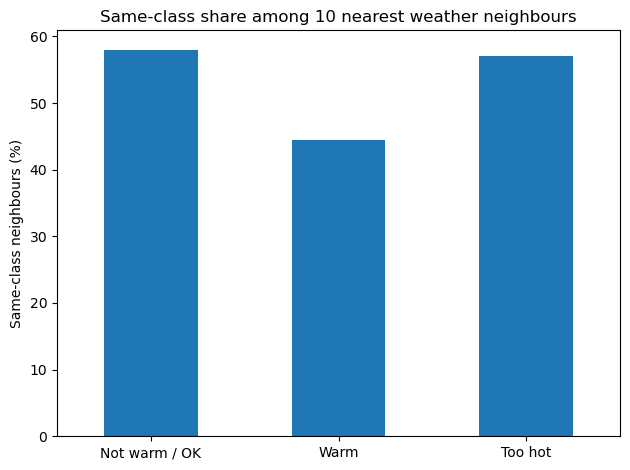

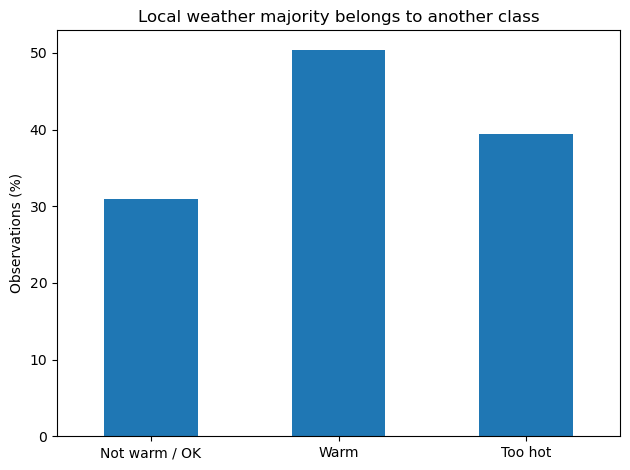

In [6]:
X = StandardScaler().fit_transform(data[FEATURES])
nn = NearestNeighbors(n_neighbors=11).fit(X)
_, idx = nn.kneighbors(X)
idx = idx[:,1:]

same_share = []
majority_wrong = []

for i, neigh in enumerate(idx):
    neigh_y = y[neigh]
    same_share.append(np.mean(neigh_y == y[i]))
    majority = np.argmax(np.bincount(neigh_y, minlength=3))
    majority_wrong.append(majority != y[i])

data["knn_same_class_share"] = same_share
data["local_majority_other_class"] = majority_wrong

knn = data.groupby("thermal_class")["knn_same_class_share"].agg(["count","mean","median","std"]).reindex(ORDER)
knn["mean_same_class_percent"] = 100*knn["mean"]
display(knn.round(3))

maj = data.groupby("thermal_class")["local_majority_other_class"].agg(["count","sum","mean"]).reindex(ORDER)
maj["percentage"] = 100*maj["mean"]
display(maj[["count","sum","percentage"]].round(2))

ax = knn["mean_same_class_percent"].plot(kind="bar")
ax.set_title("Same-class share among 10 nearest weather neighbours")
ax.set_xlabel(""); ax.set_ylabel("Same-class neighbours (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

ax = maj["percentage"].plot(kind="bar")
ax.set_title("Local weather majority belongs to another class")
ax.set_xlabel(""); ax.set_ylabel("Observations (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()


## 6. Small weather cells: how many classes occupy the same region?

Temperature is placed in 1°C bins and RH in 5% bins. We then inspect cells containing at least 5 observations.

If most cells contain more than one target class, clean decision boundaries are unlikely to exist using these variables alone.


Populated cells (n >= 5): 64
Cells with >1 class: 57
Cells with all 3 classes: 23
Percent with >1 class: 89.1 %
Percent with all 3 classes: 35.9 %


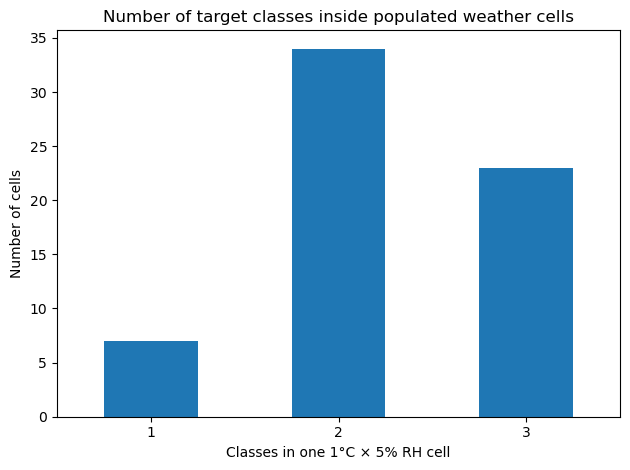

In [7]:
b = data.copy()
b["temp_bin"] = np.floor(b["temperature_c"]).astype(int)
b["rh_bin"] = (np.floor(b["relative_humidity"]/5)*5).astype(int)

cell_stats = (
    b.groupby(["temp_bin","rh_bin"])
    .agg(n=("nr","size"), n_classes=("thermal_class_code","nunique"))
    .reset_index()
)
pop = cell_stats[cell_stats["n"]>=5]

print("Populated cells (n >= 5):", len(pop))
print("Cells with >1 class:", int((pop["n_classes"]>1).sum()))
print("Cells with all 3 classes:", int((pop["n_classes"]==3).sum()))
if len(pop):
    print("Percent with >1 class:", round(100*(pop["n_classes"]>1).mean(),1), "%")
    print("Percent with all 3 classes:", round(100*(pop["n_classes"]==3).mean(),1), "%")

ax = pop["n_classes"].value_counts().sort_index().plot(kind="bar")
ax.set_title("Number of target classes inside populated weather cells")
ax.set_xlabel("Classes in one 1°C × 5% RH cell")
ax.set_ylabel("Number of cells")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()


## 7. PCA visualization using all four weather features

PCA is used only as an exploratory visualization. Heavy overlap after projecting the four weather variables into their main directions of variation supports the same conclusion.


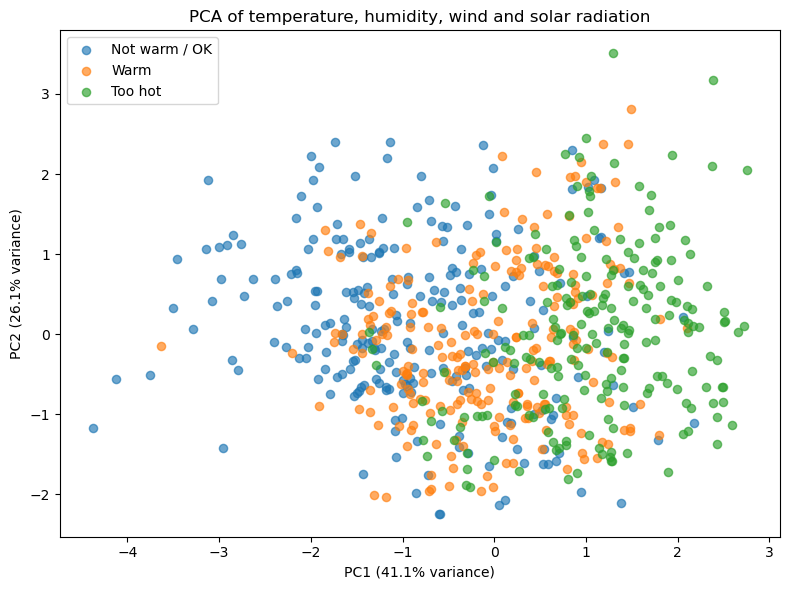

Variance explained by PC1 + PC2: 67.2 %


In [8]:
Xs = StandardScaler().fit_transform(data[FEATURES])
pca = PCA(n_components=2)
Z = pca.fit_transform(Xs)
pca_df = pd.DataFrame({"PC1":Z[:,0], "PC2":Z[:,1], "thermal_class":data["thermal_class"].values})

fig, ax = plt.subplots(figsize=(8,6))
for cls in ORDER:
    s = pca_df[pca_df["thermal_class"]==cls]
    ax.scatter(s["PC1"], s["PC2"], alpha=0.65, s=35, label=cls)
ax.set_title("PCA of temperature, humidity, wind and solar radiation")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend()
plt.tight_layout(); plt.show()

print("Variance explained by PC1 + PC2:", round(100*pca.explained_variance_ratio_.sum(),1), "%")


## 8. Predictive diagnostic: 3 classes vs binary

This is **not** intended as the final modelling experiment.

The same weather features and the same 5-fold out-of-fold procedure are used for:

- `OK / Warm / Too hot`
- `Not too hot / Too hot`

If binary prediction is much easier, it supports the hypothesis that the difficult part is the middle `Warm` boundary rather than a general failure to model thermal conditions.


,Task,OOF Macro-F1,OOF Balanced Accuracy
0,3-class: OK / Warm / Too hot,0.625,0.626
1,Binary: Not too hot / Too hot,0.763,0.792


3-class classification report:

               precision    recall  f1-score   support

Not warm / OK      0.730     0.691     0.710       246
         Warm      0.494     0.496     0.495       230
      Too hot      0.653     0.690     0.671       213

     accuracy                          0.626       689
    macro avg      0.625     0.626     0.625       689
 weighted avg      0.627     0.626     0.626       689



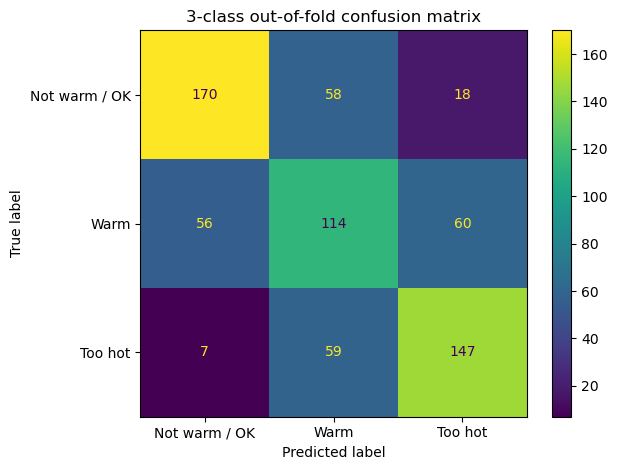

: 

In [ ]:
X = data[FEATURES]
y3 = data["thermal_class_code"].astype(int)
y2 = (y3==2).astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_svm():
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", C=3, gamma="scale", class_weight="balanced", random_state=42))
    ])

pred3 = cross_val_predict(make_svm(), X, y3, cv=cv, method="predict", n_jobs=-1)
pred2 = cross_val_predict(make_svm(), X, y2, cv=cv, method="predict", n_jobs=-1)

comparison = pd.DataFrame({
    "Task":["3-class: OK / Warm / Too hot","Binary: Not too hot / Too hot"],
    "OOF Macro-F1":[f1_score(y3,pred3,average="macro"), f1_score(y2,pred2,average="macro")],
    "OOF Balanced Accuracy":[balanced_accuracy_score(y3,pred3), balanced_accuracy_score(y2,pred2)]
})
display(comparison.round(3))

print("3-class classification report:\n")
print(classification_report(y3,pred3,labels=[0,1,2],target_names=ORDER,digits=3,zero_division=0))

cm = confusion_matrix(y3,pred3,labels=[0,1,2])
ConfusionMatrixDisplay(cm, display_labels=ORDER).plot()
plt.title("3-class out-of-fold confusion matrix")
plt.tight_layout(); plt.show()


# Mentor discussion summary

Use these points when discussing the model with your mentor:

1. **Class imbalance is not the main problem.**
2. Environmental distributions follow the expected thermal ordering but overlap heavily.
3. Respondents under identical or near-identical weather often give different labels.
4. `Warm` has especially low local class purity and is frequently surrounded by `OK` and `Too hot`.
5. Many small weather regions contain two or all three target classes.
6. A binary `Too hot vs Not too hot` task is much easier with the same inputs, showing that the middle transition boundary is the main difficulty.

## Suggested question for the mentor

> Given this genuine overlap in the available environmental feature space, should ShadeAdapt keep a 3-class population model and use personal feedback to learn each user's thermal boundaries, or use a simpler binary population model while keeping 3-level personal feedback in the app?

This notebook is intended to demonstrate the issue with **data evidence**, not just model scores.
